In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

In [2]:
env = gym.make('FrozenLake-v1')

#parameters
alpha = 0.1
gamma = 0.9
epsilon = 1
min_epsilon = 0.01
epsilon_decay = 0.9995

n_episodes = 10000

#q-table
Q = np.zeros((env.observation_space.n, env.action_space.n))

rewards_list = []

#epsilon-greedy to choose action

In [3]:
def choose_action(state):
    if np.random.uniform() < epsilon:
        action = env.action_space.sample()
    else:
        action = np.argmax(Q[state, :])

    return action

#fn to update q-table

In [4]:
def update_Q(state, action, reward, next_state, next_action):
    Q[state, action] += alpha * (reward + gamma * Q[next_state, next_action] - Q[state, action])

In [5]:
for i in range(n_episodes):
    state, info = env.reset()
    done = False
    total_reward = 0

    action = choose_action(state)

    while not done:
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        next_action = choose_action(next_state)
        update_Q(state, action, reward, next_state, next_action)

        state = next_state
        action = next_action

        total_reward += reward

    epsilon = max(min_epsilon, epsilon * epsilon_decay)
    rewards_list.append(total_reward)
    

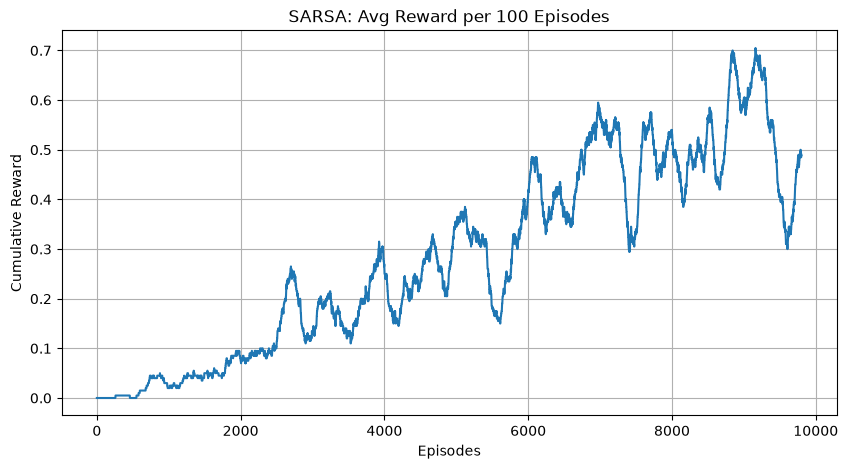

In [6]:
window = 200
moving_avg = np.convolve(rewards_list, np.ones(window)/window, mode='valid')

plt.figure(figsize=(10,5))
plt.plot(moving_avg)
plt.title('SARSA: Avg Reward per 100 Episodes')
plt.xlabel('Episodes')
plt.ylabel('Cumulative Reward')
plt.grid(True)
plt.show()